In [1]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

### Median filter for salt pepper noise removal

In [2]:
img = cv2.imread("noisysalterpepper.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

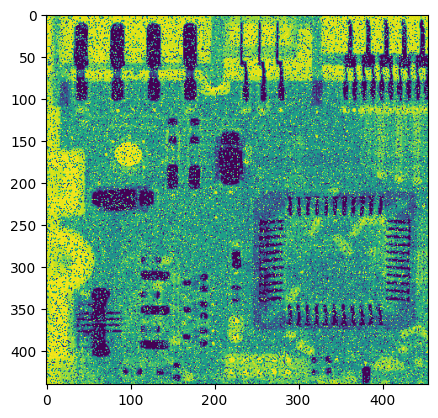

In [3]:
plt.imshow(img)

In [4]:
kernel = 1/9 *np.array([[1,1,1], [1,1,1], [1,1,1]])

In [5]:
kernel.shape

(3, 3)

In [6]:
kernel_dim = kernel.shape[0]
for i in range(img.shape[0]):
    for j in range(img.shape[1]):
        if (i < img.shape[0] - kernel_dim) and (j < img.shape[1] - kernel_dim):
            median = np.median(np.sort(img[i:i+kernel_dim, j:j+kernel_dim].reshape(-1), axis=-1))
            img[i+kernel_dim//2, j + kernel_dim//2] = median

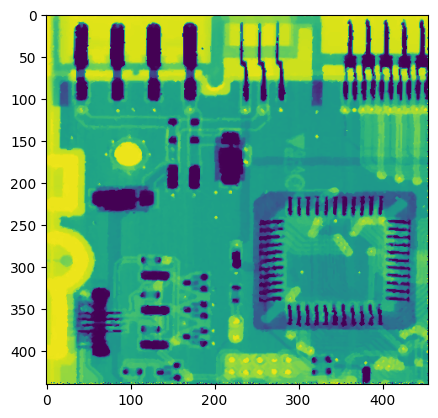

In [7]:
plt.imshow(img)

### Sobel operator

In [8]:
img = cv2.imread("bird.png")
img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
img = img.astype(np.float32)
output_img = np.zeros_like(img, dtype=np.float32)

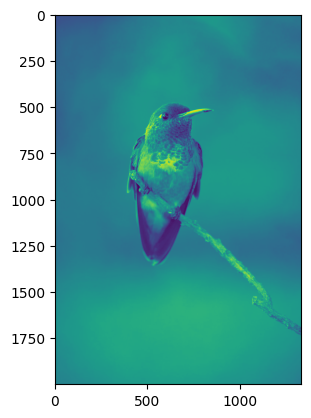

In [9]:
plt.imshow(img)

In [10]:
sobel_x = np.array([
    [-5,  -4,   0,   4,   5],
    [-8, -10,   0,  10,   8],
    [-10, -20,  0,  20,  10],
    [-8, -10,   0,  10,   8],
    [-5,  -4,   0,   4,   5]
], dtype=np.float32)


In [11]:
img.shape

(2000, 1333)

In [12]:
kernel_size = sobel_x.shape[0]

In [13]:
kernel_size

5

In [14]:
for i in range(kernel_size//2, img.shape[0]):
    for j in range(kernel_size//2, img.shape[1]):
        if (i < img.shape[0] - kernel_size) and (j < img.shape[1] - kernel_size):
            convolved_pixel_intensity = np.sum(sobel_x * img[i-kernel_size//2:i+kernel_size//2+1, j-kernel_size//2:j+kernel_size//2 + 1])
            output_img[i, j] = convolved_pixel_intensity

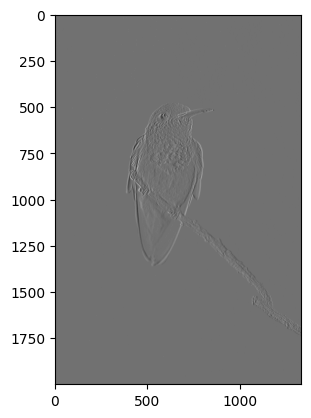

In [15]:
plt.imshow(output_img, cmap="gray")

In [16]:
magnitude = np.sqrt(output_img**2)
magnitude = magnitude / magnitude.max() * 255

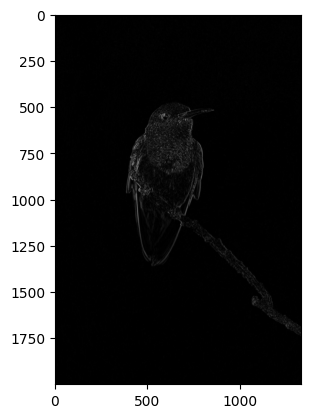

In [17]:
plt.imshow(magnitude, cmap="gray")

### Gradient of an image

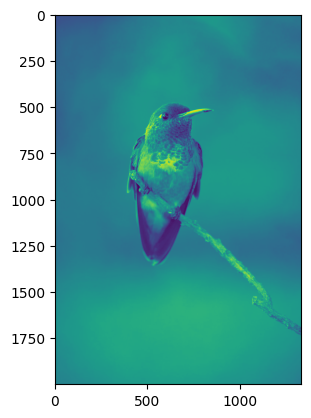

In [18]:
plt.imshow(img)

In [19]:
# img = np.array([ [12, 18, 25], [20, 30, 40], [22, 28, 35] ])
output_img = np.zeros_like(img)
kernel_dim = 3
for i in range(kernel_dim//2, img.shape[0] - kernel_dim//2):
    for j in range(kernel_dim//2, img.shape[1] - kernel_dim//2):
        gx = img[i, j + 1] - img[i, j - 1]
        gy = img[i + 1, j] - img[i - 1, j]
        g_mag = np.sqrt(gx**2 + gy**2)
        g_ang = np.arctan2(gy, gx)
        output_img[i, j] = g_mag

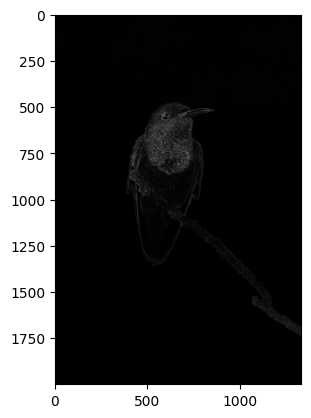

In [20]:
plt.imshow(output_img, cmap="gray")